# 06 - All-data SWOT and HF-radar kinetic-energy comparison

In [1]:
# This notebook processes HF-radar NetCDF files, extracts eastward and northward velocity components,
# and stores the cleaned data in a Zarr archive, avoiding duplicate time steps.
from pathlib import Path
import shutil
import numpy as np
import xarray as xr

# Use the repository root explicitly so the paths are stable when the notebook
# is run from VS Code, Jupyter, or the terminal.
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
raw_dir = repo_root / "data/raw/hf_radar"
years = ("2024", "2025", "2026")
zarr_path = repo_root / "data/processed/hf_radar.zarr"
rebuild_hf_radar_zarr = False
skipped_log_path = repo_root / "data/processed/hf_radar_skipped_files.txt"
zarr_path.parent.mkdir(parents=True, exist_ok=True)

files = []
for year in years:
    year_dir = raw_dir / year
    year_files = sorted(year_dir.rglob("*.nc")) if year_dir.exists() else []
    print(f"{year}: found {len(year_files)} NetCDF files in {year_dir}")
    files.extend(year_files)

files = sorted(files)
print(f"total files found: {len(files)}")

if not files:
    raise FileNotFoundError(
        f"No .nc files found below {raw_dir} for years {', '.join(years)}."
    )

velocity_vars = ("ewct", "nsct")  # eastward and northward velocity components


def prep(ds, source_path):
    """Keep eastward/northward velocities and ensure a sorted time axis."""
    missing = [name for name in velocity_vars if name not in ds.data_vars]
    if missing:
        raise KeyError(f"{source_path} is missing variables: {missing}")
    if "time" not in ds.dims:
        raise KeyError(f"{source_path} does not contain a time dimension")

    return ds[list(velocity_vars)].sortby("time")


def open_prepared_dataset(file_path):
    """Open one NetCDF file and return a loaded, safe dataset."""
    try:
        with xr.open_dataset(file_path) as ds:
            prepared = prep(ds, file_path).load()
    except Exception as exc:
        return None, f"{file_path}\t{type(exc).__name__}: {exc}"

    return prepared.chunk({"time": 1, "latitude": 75, "longitude": 150}), None


# Inspect the first readable file to confirm variable and dimension names.
for first_file in files:
    ds0, error = open_prepared_dataset(first_file)
    if ds0 is not None:
        print(ds0)
        ds0.close()
        break
else:
    raise OSError("No readable HF-radar NetCDF files were found.")

if zarr_path.exists() and not rebuild_hf_radar_zarr:
    print(f"Using existing HF-radar archive: {zarr_path}")
    ds_all = xr.open_zarr(zarr_path, consolidated=True)
    skipped_files = []
    skipped_duplicate_times = 0
    written = ds_all.sizes["time"]
else:
    if zarr_path.exists():
        if zarr_path.is_dir():
            shutil.rmtree(zarr_path)
        else:
            zarr_path.unlink()

    seen_times = set()
    written = 0
    skipped_duplicate_times = 0
    skipped_files = []

    for i, file_path in enumerate(files, start=1):
        ds, error = open_prepared_dataset(file_path)

        if ds is None:
            skipped_files.append(error)
            if len(skipped_files) <= 10:
                print(f"skipping unreadable file: {error}")
            continue

        time_values = np.asarray(ds.time.values).ravel()
        time_keys = [np.datetime_as_string(t, unit="ns") for t in time_values]
        keep = np.array([key not in seen_times for key in time_keys], dtype=bool)

        if not keep.any():
            skipped_duplicate_times += len(time_keys)
            ds.close()
            continue

        if not keep.all():
            skipped_duplicate_times += int((~keep).sum())
            ds = ds.isel(time=keep)
            time_keys = [key for key, keep_one in zip(time_keys, keep) if keep_one]

        mode = "w" if written == 0 else "a"
        kwargs = {} if written == 0 else {"append_dim": "time"}
        ds.to_zarr(
            zarr_path,
            mode=mode,
            consolidated=True,
            zarr_format=2,
            **kwargs,
        )
        ds.close()

        seen_times.update(time_keys)
        written += len(time_keys)

        if i == 1 or i % 500 == 0 or i == len(files):
            print(f"processed {i}/{len(files)} files; written {written} time steps")

    if skipped_files:
        skipped_log_path.write_text("\n".join(skipped_files) + "\n")
        print(
            f"skipped {len(skipped_files)} unreadable files; "
            f"details written to {skipped_log_path}"
        )
    else:
        skipped_log_path.unlink(missing_ok=True)

    if written == 0:
        raise OSError("No readable, non-duplicate HF-radar time steps were written to Zarr.")

    ds_all = xr.open_zarr(zarr_path, consolidated=True)

print(ds_all)
print("variables:", list(ds_all.data_vars))
print("time range:", ds_all.time.values[0], "to", ds_all.time.values[-1])
print("time steps:", ds_all.sizes["time"])
print("unreadable files skipped:", len(skipped_files))
print("duplicate timestamps skipped:", skipped_duplicate_times)
print("duplicate timestamps in Zarr:", int(ds_all.time.to_index().duplicated().sum()))

2024: found 719 NetCDF files in <repo>/data/raw/hf_radar/2024
2025: found 17430 NetCDF files in <repo>/data/raw/hf_radar/2025
2026: found 6459 NetCDF files in <repo>/data/raw/hf_radar/2026
total files found: 24608
<xarray.Dataset> Size: 92kB
Dimensions:    (time: 1, latitude: 75, longitude: 150)
Coordinates:
  * time       (time) datetime64[ns] 8B 2024-11-10T15:30:00
  * latitude   (latitude) float64 600B -33.73 -33.78 -33.84 ... -37.67 -37.73
  * longitude  (longitude) float64 1kB 19.0 19.07 19.13 ... 28.79 28.86 28.93
Data variables:
    ewct       (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
    nsct       (time, latitude, longitude) float32 45kB dask.array<chunksize=(1, 75, 150), meta=np.ndarray>
Attributes: (12/35)
    max_gdop:                  -1.0
    max_err:                   -1.0
    max_dist:                  -1.0
    smooth:                    0
    id:                        South_Africa_HF_Radar_20201231
    naming_authorit

In [2]:
# Mean and eddy kinetic energy from HF-radar surface currents (as in calc_kinetic.m):
#   MKE = 0.5 * (mean(u)^2 + mean(v)^2)
#   EKE = 0.5 * (mean(u'^2) + mean(v'^2)), where u' = u - mean(u)
# Means are taken over the full time record at each grid point.

if {"mke", "eke"}.issubset(ds_all.data_vars):
    print("MKE and EKE already exist in the HF-radar Zarr archive; skipping calculation.")
else:
    u = ds_all["ewct"]
    v = ds_all["nsct"]

    # drop any singleton depth dimension if present
    for extra_dim in ("depth", "DEPTH"):
        if extra_dim in u.dims and u.sizes[extra_dim] == 1:
            u = u.isel({extra_dim: 0}, drop=True)
            v = v.isel({extra_dim: 0}, drop=True)

    u_bar = u.mean("time", skipna=True)
    v_bar = v.mean("time", skipna=True)

    u_prime = u - u_bar
    v_prime = v - v_bar

    mke = (0.5 * (u_bar**2 + v_bar**2)).astype("float32")
    eke = (
        0.5 * ((u_prime**2).mean("time", skipna=True) + (v_prime**2).mean("time", skipna=True))
    ).astype("float32")

    n_obs = u.notnull().sum("time").astype("int32")

    mke.attrs = {
        "long_name": "mean kinetic energy per unit mass",
        "units": "m2 s-2",
        "description": "0.5 * (time-mean(ewct)^2 + time-mean(nsct)^2)",
    }
    eke.attrs = {
        "long_name": "eddy kinetic energy per unit mass",
        "units": "m2 s-2",
        "description": "0.5 * (mean(ewct'^2) + mean(nsct'^2)) with primes relative to the time mean",
    }
    u_bar.attrs = {"long_name": "time-mean eastward velocity", "units": "m s-1"}
    v_bar.attrs = {"long_name": "time-mean northward velocity", "units": "m s-1"}
    n_obs.attrs = {"long_name": "number of valid time steps used per grid point"}

    ke_ds = xr.Dataset(
        {
            "u_mean": u_bar.astype("float32"),
            "v_mean": v_bar.astype("float32"),
            "mke": mke,
            "eke": eke,
            "n_obs": n_obs,
        }
    ).compute()

    for variable in ke_ds.variables:
        ke_ds[variable].encoding = {}

    # Append the new time-independent fields to the existing HF-radar archive.
    ke_ds.to_zarr(zarr_path, mode="a", consolidated=True, zarr_format=2)

    ds_all = xr.open_zarr(zarr_path, consolidated=True)

print("variables now in archive:", list(ds_all.data_vars))
print(
    "MKE range (m2 s-2):",
    float(ds_all["mke"].min()),
    "to",
    float(ds_all["mke"].max()),
)
print(
    "EKE range (m2 s-2):",
    float(ds_all["eke"].min()),
    "to",
    float(ds_all["eke"].max()),
)

MKE and EKE already exist in the HF-radar Zarr archive; skipping calculation.
variables now in archive: ['eke', 'ewct', 'mke', 'n_obs', 'nsct', 'u_mean', 'v_mean']
MKE range (m2 s-2): 1.4210772860678844e-05 to 7.43385648727417
EKE range (m2 s-2): 0.0 to 2.5999929904937744


In [3]:
# This notebook processes SWOT L3 data to extract filtered velocity fields within a specified geographic bounding box
# and stores the results in a Zarr archive.
import re
import shutil

import numpy as np
import xarray as xr

swot_raw_dir = repo_root / "data/raw/swot_l3_expert"

if not swot_raw_dir.is_dir():
    raise FileNotFoundError(f"SWOT directory not found: {swot_raw_dir}")

swot_files_all = sorted(swot_raw_dir.rglob("*.nc"))
print(f"found {len(swot_files_all)} SWOT L3 files in {swot_raw_dir}")
skipped_swot_files = []

lon_min, lon_max = 20.0, 28.0
lat_min, lat_max = -38.0, -33.0

swot_out_zarr_path = repo_root / "data/processed/swot_filtered_velocity.zarr"
rebuild_swot_zarr = False
swot_out_zarr_path.parent.mkdir(parents=True, exist_ok=True)

swot_velocity_vars = ("ugos_filtered", "vgos_filtered")
time_pattern = re.compile(r"(\d{8}T\d{6})")

if not swot_files_all:
    raise FileNotFoundError(f"No .nc files found below {swot_raw_dir}")


def extract_pass_time(file_path):
    match = time_pattern.search(file_path.name)
    if match is None:
        return None

    timestamp = match.group(1)
    return np.datetime64(
        f"{timestamp[:4]}-{timestamp[4:6]}-{timestamp[6:8]}T"
        f"{timestamp[9:11]}:{timestamp[11:13]}:{timestamp[13:15]}",
        "s",
    )


def prep_swot(ds, file_path):
    missing = [name for name in swot_velocity_vars if name not in ds.data_vars]
    if missing:
        raise KeyError(f"{file_path} is missing variables: {missing}")

    pass_time = extract_pass_time(file_path)
    if pass_time is None:
        raise ValueError("No timestamp found in filename")

    latitude = ds["latitude"]
    longitude = ds["longitude"]

    region_mask = (
        (latitude >= lat_min)
        & (latitude <= lat_max)
        & (longitude >= lon_min)
        & (longitude <= lon_max)
    )

    prepared = ds[list(swot_velocity_vars)].where(region_mask).astype("float32")
    prepared = prepared.expand_dims(time=[pass_time])

    # Geolocation changes between SWOT passes, so store it along the time dimension.
    prepared = prepared.assign_coords(
        latitude=latitude.expand_dims(time=[pass_time]),
        longitude=longitude.expand_dims(time=[pass_time]),
    )

    for variable in prepared.variables:
        prepared[variable].encoding = {}

    prepared["time"].encoding = {
        "dtype": "int64",
        "units": "seconds since 1970-01-01 00:00:00",
        "calendar": "standard",
    }

    for variable in swot_velocity_vars:
        prepared[variable].encoding = {
            "dtype": "float32",
            "_FillValue": np.float32(np.nan),
        }

    return prepared.load()


hf_time_start = np.asarray(ds_all.time.values).min()
hf_time_end = np.asarray(ds_all.time.values).max()
filtered_swot_files = []
for file_path in swot_files_all:
    pass_time = extract_pass_time(file_path)
    if pass_time is None or not (hf_time_start <= pass_time <= hf_time_end):
        skipped_swot_files.append(
            f"{file_path}\toutside HF period or missing filename timestamp"
        )
        continue
    filtered_swot_files.append(file_path)
swot_files_all = filtered_swot_files
print(
    f"selected {len(swot_files_all)} SWOT files within HF period "
    f"{hf_time_start} to {hf_time_end}"
)

if swot_out_zarr_path.exists() and not rebuild_swot_zarr:
    print(f"Using existing SWOT archive: {swot_out_zarr_path}")
    swot_out_ds = xr.open_zarr(
        swot_out_zarr_path,
        consolidated=True,
    )
    written_passes = swot_out_ds.sizes["time"]
    swot_time_start = np.asarray(swot_out_ds.time.values).min()
    swot_time_end = np.asarray(swot_out_ds.time.values).max()
    if swot_time_start < hf_time_start or swot_time_end > hf_time_end:
        raise ValueError(
            f"Existing SWOT archive time range {swot_time_start} to "
            f"{swot_time_end} extends outside HF-radar period "
            f"{hf_time_start} to {hf_time_end}; rebuild SWOT archive."
        )
else:
    if swot_out_zarr_path.exists():
        if swot_out_zarr_path.is_dir():
            shutil.rmtree(swot_out_zarr_path)
        else:
            swot_out_zarr_path.unlink()

    written_passes = 0

    for i, file_path in enumerate(swot_files_all, start=1):
        try:
            with xr.open_dataset(file_path) as ds:
                prepared = prep_swot(ds, file_path)
        except Exception as exc:
            skipped_swot_files.append(
                f"{file_path}\t{type(exc).__name__}: {exc}"
            )
            continue

        if not np.isfinite(prepared["ugos_filtered"].values).any():
            prepared.close()
            continue

        mode = "w" if written_passes == 0 else "a"
        kwargs = {} if written_passes == 0 else {"append_dim": "time"}

        prepared.to_zarr(
            swot_out_zarr_path,
            mode=mode,
            consolidated=True,
            zarr_format=2,
            **kwargs,
        )
        prepared.close()

        written_passes += 1

        if i == 1 or i % 50 == 0 or i == len(swot_files_all):
            print(
                f"processed {i}/{len(swot_files_all)} files; "
                f"written {written_passes} passes"
            )

    if written_passes == 0:
        raise OSError("No SWOT passes with data inside the bounding box were written.")

    swot_out_ds = xr.open_zarr(
        swot_out_zarr_path,
        consolidated=True,
    )

print(swot_out_ds)
print("variables:", list(swot_out_ds.data_vars))
print("passes written:", swot_out_ds.sizes["time"])
print(
    "time range:",
    swot_out_ds.time.values[0],
    "to",
    swot_out_ds.time.values[-1],
)
print("files skipped:", len(skipped_swot_files))

found 688 SWOT L3 files in <repo>/data/raw/swot_l3_expert
selected 300 SWOT files within HF period 2024-11-10T15:30:00.000000000 to 2026-04-21T23:30:00.000000000
processed 1/300 files; written 1 passes
processed 100/300 files; written 63 passes
processed 150/300 files; written 96 passes
processed 200/300 files; written 128 passes
processed 250/300 files; written 160 passes
processed 300/300 files; written 192 passes
<xarray.Dataset> Size: 3GB
Dimensions:        (time: 192, num_lines: 9860, num_pixels: 69)
Coordinates:
  * time           (time) datetime64[ns] 2kB 2024-11-11T01:07:13 ... 2026-04-...
    latitude       (time, num_lines, num_pixels) float64 1GB dask.array<chunksize=(1, 2465, 18), meta=np.ndarray>
    longitude      (time, num_lines, num_pixels) float64 1GB dask.array<chunksize=(1, 2465, 18), meta=np.ndarray>
Dimensions without coordinates: num_lines, num_pixels
Data variables:
    ugos_filtered  (time, num_lines, num_pixels) float32 523MB dask.array<chunksize=(1, 2465, 35)

In [4]:
# Calculate MKE and EKE from all valid SWOT overpasses on the fixed 6 km grid.
# Each overpass is first averaged within cells using its own time-varying coordinates.

import cartopy.crs as ccrs

# Keep this grid definition here so the SWOT calculation can run immediately after
# the SWOT archive cell. Cell 6 reuses the same edges and cell-id function.
grid_spacing_m = 6_000
data_crs = ccrs.PlateCarree()
grid_crs = ccrs.UTM(zone=34, southern_hemisphere=True)

domain_lon = np.array([lon_min, lon_max, lon_max, lon_min])
domain_lat = np.array([lat_min, lat_min, lat_max, lat_max])
domain_xy = grid_crs.transform_points(data_crs, domain_lon, domain_lat)

x_edges = np.arange(
    np.floor(domain_xy[:, 0].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 0].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
y_edges = np.arange(
    np.floor(domain_xy[:, 1].min() / grid_spacing_m) * grid_spacing_m,
    np.ceil(domain_xy[:, 1].max() / grid_spacing_m) * grid_spacing_m + grid_spacing_m,
    grid_spacing_m,
)
n_x = len(x_edges) - 1
n_y = len(y_edges) - 1


def grid_cell_ids(longitude, latitude):
    """Return flattened 6 km-grid indices for a longitude/latitude field."""
    longitude = np.asarray(longitude)
    latitude = np.asarray(latitude)
    if longitude.ndim == 1 and latitude.ndim == 1:
        longitude, latitude = np.meshgrid(longitude, latitude)
    else:
        longitude, latitude = np.broadcast_arrays(longitude, latitude)

    xy = grid_crs.transform_points(data_crs, longitude.ravel(), latitude.ravel())
    ix = np.digitize(xy[:, 0], x_edges) - 1
    iy = np.digitize(xy[:, 1], y_edges) - 1
    inside = (
        np.isfinite(xy[:, 0])
        & np.isfinite(xy[:, 1])
        & (ix >= 0)
        & (ix < n_x)
        & (iy >= 0)
        & (iy < n_y)
    )
    cell_ids = np.full(xy.shape[0], -1, dtype=int)
    cell_ids[inside] = iy[inside] * n_x + ix[inside]
    return cell_ids


swot_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)
fixed_grid_energy_exists = {
    "mke",
    "eke",
    "grid_latitude",
    "grid_longitude",
}.issubset(swot_ds.variables)

if fixed_grid_energy_exists:
    print("Fixed-grid SWOT MKE and EKE already exist; skipping calculation.")
    swot_out_ds = swot_ds
elif {"mke", "eke"}.issubset(swot_ds.data_vars):
    raise ValueError(
        "The SWOT archive contains native-swath MKE/EKE but not fixed-grid fields. "
        "Set rebuild_swot_zarr = True, rerun the SWOT archive cell, then rerun this cell."
    )
else:
    n_passes = swot_ds.sizes["time"]
    u_grid_values = np.full((n_passes, n_y * n_x), np.nan, dtype="float32")
    v_grid_values = np.full((n_passes, n_y * n_x), np.nan, dtype="float32")

    for time_index in range(n_passes):
        u_values = swot_ds["ugos_filtered"].isel(time=time_index).compute().values.ravel()
        v_values = swot_ds["vgos_filtered"].isel(time=time_index).compute().values.ravel()
        cell_ids = grid_cell_ids(
            swot_ds["longitude"].isel(time=time_index).compute().values,
            swot_ds["latitude"].isel(time=time_index).compute().values,
        )
        valid = np.isfinite(u_values) & np.isfinite(v_values) & (cell_ids >= 0)
        if valid.any():
            valid_cells = cell_ids[valid]
            counts = np.bincount(valid_cells, minlength=n_y * n_x)
            u_sums = np.bincount(valid_cells, weights=u_values[valid], minlength=n_y * n_x)
            v_sums = np.bincount(valid_cells, weights=v_values[valid], minlength=n_y * n_x)
            occupied = counts > 0
            u_grid_values[time_index, occupied] = u_sums[occupied] / counts[occupied]
            v_grid_values[time_index, occupied] = v_sums[occupied] / counts[occupied]

        if (time_index + 1) % 50 == 0 or time_index + 1 == n_passes:
            print(f"SWOT fixed-grid aggregation: {time_index + 1}/{n_passes} passes")

    grid_y = np.arange(n_y)
    grid_x = np.arange(n_x)
    grid_x_centres = 0.5 * (x_edges[:-1] + x_edges[1:])
    grid_y_centres = 0.5 * (y_edges[:-1] + y_edges[1:])
    grid_x_mesh, grid_y_mesh = np.meshgrid(grid_x_centres, grid_y_centres)
    grid_lonlat = data_crs.transform_points(grid_crs, grid_x_mesh, grid_y_mesh)
    grid_longitude = grid_lonlat[..., 0]
    grid_latitude = grid_lonlat[..., 1]

    u_grid = xr.DataArray(
        u_grid_values.reshape(n_passes, n_y, n_x),
        dims=("time", "grid_y", "grid_x"),
        coords={"time": swot_ds.time, "grid_y": grid_y, "grid_x": grid_x},
        name="swot_u_fixed_grid",
    )
    v_grid = xr.DataArray(
        v_grid_values.reshape(n_passes, n_y, n_x),
        dims=("time", "grid_y", "grid_x"),
        coords={"time": swot_ds.time, "grid_y": grid_y, "grid_x": grid_x},
        name="swot_v_fixed_grid",
    )

    u_mean_swot = u_grid.mean("time", skipna=True)
    v_mean_swot = v_grid.mean("time", skipna=True)
    mke_swot = (0.5 * (u_mean_swot**2 + v_mean_swot**2)).astype("float32")
    eke_swot = (
        0.5
        * (
            ((u_grid - u_mean_swot) ** 2).mean("time", skipna=True)
            + ((v_grid - v_mean_swot) ** 2).mean("time", skipna=True)
        )
    ).astype("float32")
    n_obs_swot = (np.isfinite(u_grid) & np.isfinite(v_grid)).sum("time").astype("int32")

    swot_ke_ds = xr.Dataset(
        {
            "mke": mke_swot,
            "eke": eke_swot,
            "u_mean": u_mean_swot.astype("float32"),
            "v_mean": v_mean_swot.astype("float32"),
            "n_obs": n_obs_swot,
        },
        coords={
            "grid_longitude": (("grid_y", "grid_x"), grid_longitude),
            "grid_latitude": (("grid_y", "grid_x"), grid_latitude),
        },
    )
    swot_ke_ds["mke"].attrs = {
        "long_name": "mean kinetic energy per unit mass",
        "units": "m2 s-2",
        "description": "0.5 * (time-mean fixed-grid u^2 + time-mean fixed-grid v^2)",
    }
    swot_ke_ds["eke"].attrs = {
        "long_name": "eddy kinetic energy per unit mass",
        "units": "m2 s-2",
        "description": "0.5 * (mean fixed-grid u'^2 + mean fixed-grid v'^2)",
    }
    swot_ke_ds["n_obs"].attrs = {
        "long_name": "number of SWOT overpasses contributing to each fixed grid cell",
    }
    swot_ke_ds.attrs["grid_spacing_m"] = grid_spacing_m
    swot_ke_ds.attrs["grid_projection"] = "UTM zone 34 south"

    for variable in swot_ke_ds.variables:
        swot_ke_ds[variable].encoding = {}
    swot_ke_ds.to_zarr(
        swot_out_zarr_path,
        mode="a",
        consolidated=True,
        zarr_format=2,
    )
    swot_out_ds = xr.open_zarr(swot_out_zarr_path, consolidated=True)

print("variables now in archive:", list(swot_out_ds.data_vars))
print(
    "SWOT MKE range (m2 s-2):",
    float(swot_out_ds["mke"].min()),
    "to",
    float(swot_out_ds["mke"].max()),
)
print(
    "SWOT EKE range (m2 s-2):",
    float(swot_out_ds["eke"].min()),
    "to",
    float(swot_out_ds["eke"].max()),
)

SWOT fixed-grid aggregation: 50/192 passes
SWOT fixed-grid aggregation: 100/192 passes
SWOT fixed-grid aggregation: 150/192 passes
SWOT fixed-grid aggregation: 192/192 passes
variables now in archive: ['eke', 'mke', 'n_obs', 'u_mean', 'ugos_filtered', 'v_mean', 'vgos_filtered']
SWOT MKE range (m2 s-2): 2.62184380517283e-06 to 12.62684440612793
SWOT EKE range (m2 s-2): 0.0 to 3.315192222595215


Loading existing snapshot_count from <repo>/data/processed/hf_radar.zarr
Loading existing overpass_count from <repo>/data/processed/swot_filtered_velocity.zarr


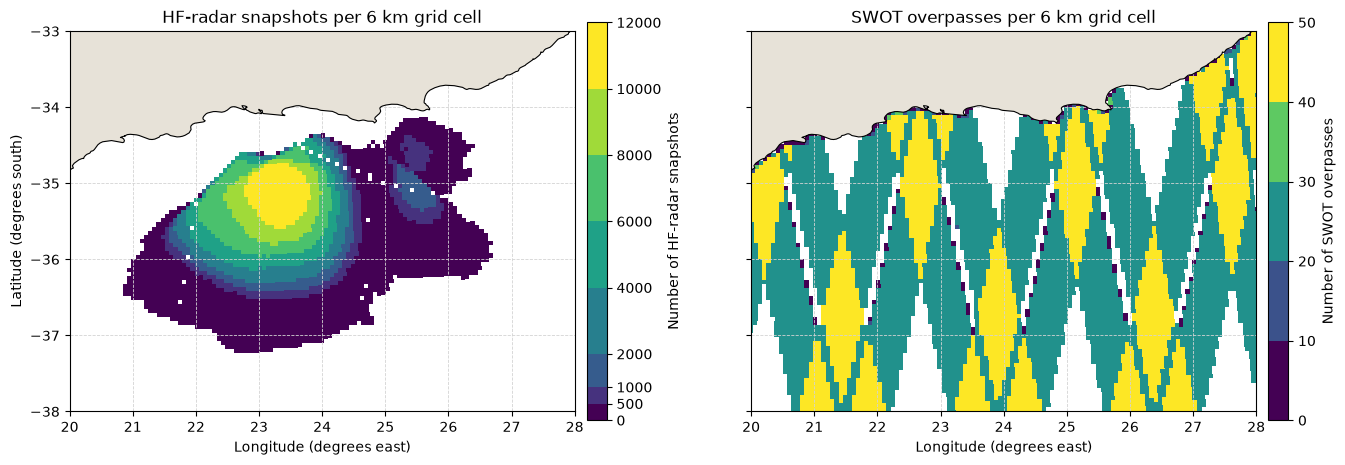

In [42]:
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from shapely.geometry import box

hf_count_name = "snapshot_count"
swot_count_name = "overpass_count"
hf_count_archive = xr.open_zarr(zarr_path, consolidated=True)
swot_count_archive = xr.open_zarr(swot_out_zarr_path, consolidated=True)


def count_distinct_passes(u_velocity, v_velocity, cell_ids, label):
    """Count time steps containing one or more valid vectors per grid cell."""
    counts = np.zeros(n_x * n_y, dtype=np.int32)

    for time_index in range(u_velocity.sizes["time"]):
        u_slice = np.asarray(u_velocity.isel(time=time_index).values).ravel()
        v_slice = np.asarray(v_velocity.isel(time=time_index).values).ravel()
        current_cell_ids = cell_ids[time_index] if cell_ids.ndim > 1 else cell_ids
        valid_cells = current_cell_ids[
            np.isfinite(u_slice)
            & np.isfinite(v_slice)
            & (current_cell_ids >= 0)
        ]
        counts[np.unique(valid_cells)] += 1

        if (time_index + 1) % 500 == 0 or time_index + 1 == u_velocity.sizes["time"]:
            print(f"{label}: processed {time_index + 1}/{u_velocity.sizes['time']} time steps")

    return counts.reshape(n_y, n_x)


def save_fixed_grid_count(archive_path, variable_name, values, description):
    """Append a fixed-grid count variable to an existing Zarr archive."""
    count_ds = xr.Dataset(
        {
            variable_name: (("grid_y", "grid_x"), values.astype("int32")),
        },
        coords={
            "grid_y": np.arange(n_y),
            "grid_x": np.arange(n_x),
        },
    )
    count_ds[variable_name].attrs = {
        "long_name": description,
        "units": "count",
    }
    for variable in count_ds.variables:
        count_ds[variable].encoding = {}
    count_ds.to_zarr(
        archive_path,
        mode="a",
        consolidated=True,
        zarr_format=2,
    )


if hf_count_name in hf_count_archive.data_vars:
    print(f"Loading existing {hf_count_name} from {zarr_path}")
    hf_snapshot_count = hf_count_archive[hf_count_name].load().values
else:
    print(f"Calculating and adding {hf_count_name} to {zarr_path}")
    hf_cell_ids = grid_cell_ids(ds_all.longitude.values, ds_all.latitude.values)
    hf_snapshot_count = count_distinct_passes(
        ds_all["ewct"],
        ds_all["nsct"],
        hf_cell_ids,
        "HF-radar",
    )
    save_fixed_grid_count(
        zarr_path,
        hf_count_name,
        hf_snapshot_count,
        "number of HF-radar snapshots per fixed grid cell",
    )

if swot_count_name in swot_count_archive.data_vars:
    print(f"Loading existing {swot_count_name} from {swot_out_zarr_path}")
    swot_overpass_count = swot_count_archive[swot_count_name].load().values
else:
    print(f"Calculating and adding {swot_count_name} to {swot_out_zarr_path}")
    swot_cell_ids = np.stack(
        [
            grid_cell_ids(
                swot_out_ds.longitude.isel(time=time_index).compute().values,
                swot_out_ds.latitude.isel(time=time_index).compute().values,
            )
            for time_index in range(swot_out_ds.sizes["time"])
        ]
    )
    swot_overpass_count = count_distinct_passes(
        swot_out_ds["ugos_filtered"],
        swot_out_ds["vgos_filtered"],
        swot_cell_ids,
        "SWOT",
    )
    save_fixed_grid_count(
        swot_out_zarr_path,
        swot_count_name,
        swot_overpass_count,
        "number of SWOT overpasses per fixed grid cell",
    )

# Transform projected grid edges back to longitude/latitude for standard plotting axes.
grid_x, grid_y = np.meshgrid(x_edges, y_edges)
grid_lonlat = data_crs.transform_points(grid_crs, grid_x, grid_y)
grid_lon = grid_lonlat[..., 0]
grid_lat = grid_lonlat[..., 1]
land_path = repo_root / "data/raw/basemaps/ne_10m_land.zip"
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))

figure, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
figure.subplots_adjust(left=0.08, right=0.94, bottom=0.12, top=0.90, wspace=0.12)

hf_boundaries = np.array([0, 500, 1_000, 2_000, 4_000, 6_000, 8_000, 10_000, 12_000])
hf_cmap = plt.get_cmap("viridis", len(hf_boundaries) - 1)
hf_norm = mcolors.BoundaryNorm(hf_boundaries, hf_cmap.N, clip=True)
swot_boundaries = np.arange(0, 51, 10)
swot_cmap = plt.get_cmap("viridis", len(swot_boundaries) - 1)
swot_norm = mcolors.BoundaryNorm(swot_boundaries, swot_cmap.N, clip=True)

for axis, counts, title, colourbar_label in zip(
    axes,
    (hf_snapshot_count, swot_overpass_count),
    ("HF-radar snapshots per 6 km grid cell", "SWOT overpasses per 6 km grid cell"),
    ("Number of HF-radar snapshots", "Number of SWOT overpasses"),
):
    land.plot(ax=axis, color="#e7e2d8", zorder=2)
    land.boundary.plot(ax=axis, color="black", linewidth=0.8, zorder=3)
    is_swot = title.startswith("SWOT")
    boundaries = swot_boundaries if is_swot else hf_boundaries
    cmap = swot_cmap if is_swot else hf_cmap
    norm = swot_norm if is_swot else hf_norm
    mesh = axis.pcolormesh(
        grid_lon,
        grid_lat,
        np.ma.masked_where(counts == 0, counts),
        shading="auto",
        cmap=cmap,
        norm=norm,
        zorder=1,
    )
    axis.set_xlim(lon_min, lon_max)
    axis.set_ylim(lat_min, lat_max)
    axis.set_title(title)
    axis.set_xlabel("Longitude (degrees east)")
    axis.grid(color="lightgrey", linestyle="--", linewidth=0.6)
    colourbar = figure.colorbar(
        mesh,
        ax=axis,
        shrink=0.85,
        pad=0.02,
        ticks=boundaries,
        boundaries=boundaries,
        spacing="proportional",
    )
    colourbar.set_label(colourbar_label)

axes[0].set_ylabel("Latitude (degrees south)")
plt.show()

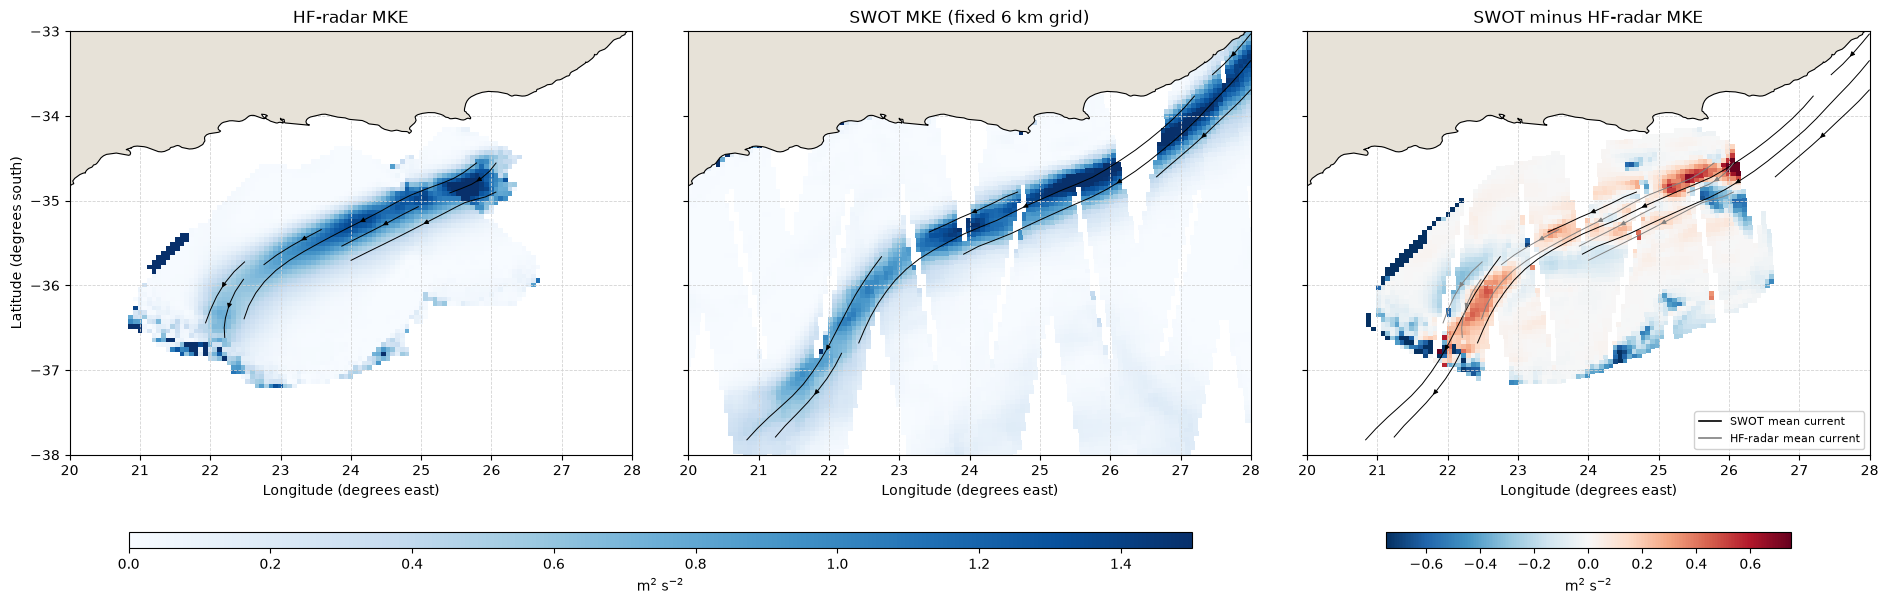

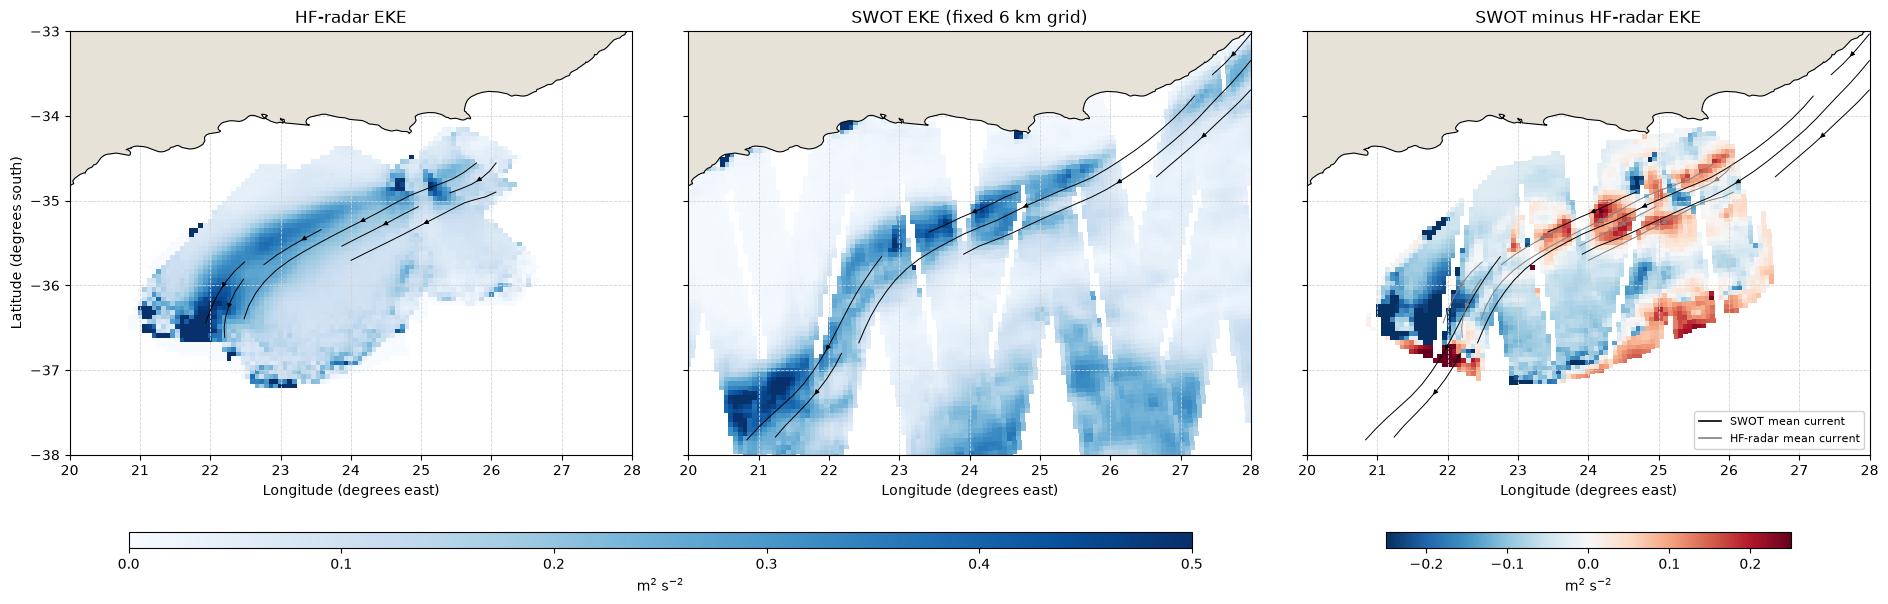

In [31]:
# Compare HF-radar fields with SWOT MKE/EKE calculated directly on the fixed 6 km grid.
# HF fields are evaluated on the SWOT grid only for the difference panels; SWOT NaNs
# remain NaN and are never filled by nearest-neighbour extrapolation.

import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from shapely.geometry import box

hf_ke_ds = xr.open_zarr(zarr_path, consolidated=True)[["mke", "eke", "u_mean", "v_mean"]]
swot_archive = xr.open_zarr(swot_out_zarr_path, consolidated=True)
swot_ke_ds_loaded = swot_archive[["mke", "eke", "grid_latitude", "grid_longitude"]]

hf_lon2d, hf_lat2d = np.meshgrid(hf_ke_ds.longitude.values, hf_ke_ds.latitude.values)
swot_lon2d = swot_ke_ds_loaded["grid_longitude"].values
swot_lat2d = swot_ke_ds_loaded["grid_latitude"].values
swot_mke = swot_ke_ds_loaded["mke"].values
swot_eke = swot_ke_ds_loaded["eke"].values
hf_mke = hf_ke_ds["mke"].values
hf_eke = hf_ke_ds["eke"].values
hf_u_mean = hf_ke_ds["u_mean"].values
hf_v_mean = hf_ke_ds["v_mean"].values

if {"u_mean", "v_mean"}.issubset(swot_archive.data_vars):
    swot_u_mean = swot_archive["u_mean"].values
    swot_v_mean = swot_archive["v_mean"].values
else:
    swot_u_mean = np.full((n_y, n_x), np.nan, dtype="float32")
    swot_v_mean = np.full((n_y, n_x), np.nan, dtype="float32")
    swot_u_sum = np.zeros((n_y, n_x), dtype="float64")
    swot_v_sum = np.zeros((n_y, n_x), dtype="float64")
    swot_vector_count = np.zeros((n_y, n_x), dtype="int32")
    swot_cell_ids = np.stack(
        [
            grid_cell_ids(
                swot_out_ds.longitude.isel(time=time_index).compute().values,
                swot_out_ds.latitude.isel(time=time_index).compute().values,
            )
            for time_index in range(swot_out_ds.sizes["time"])
        ]
    )
    for time_index in range(swot_out_ds.sizes["time"]):
        u_values = swot_out_ds["ugos_filtered"].isel(time=time_index).compute().values.ravel()
        v_values = swot_out_ds["vgos_filtered"].isel(time=time_index).compute().values.ravel()
        cell_ids = swot_cell_ids[time_index]
        valid = np.isfinite(u_values) & np.isfinite(v_values) & (cell_ids >= 0)
        if valid.any():
            valid_cells = cell_ids[valid]
            swot_u_sum += np.bincount(
                valid_cells,
                weights=u_values[valid],
                minlength=n_y * n_x,
            ).reshape(n_y, n_x)
            swot_v_sum += np.bincount(
                valid_cells,
                weights=v_values[valid],
                minlength=n_y * n_x,
            ).reshape(n_y, n_x)
            swot_vector_count += np.bincount(
                valid_cells,
                minlength=n_y * n_x,
            ).reshape(n_y, n_x)
    valid_mean = swot_vector_count > 0
    swot_u_mean[valid_mean] = (swot_u_sum[valid_mean] / swot_vector_count[valid_mean]).astype("float32")
    swot_v_mean[valid_mean] = (swot_v_sum[valid_mean] / swot_vector_count[valid_mean]).astype("float32")

land_path = repo_root / "data/raw/basemaps/ne_10m_land.zip"
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))


def evaluate_hf_on_swot_grid(source_values):
    """Linearly evaluate HF values on the fixed SWOT grid, leaving gaps as NaN."""
    valid = np.isfinite(hf_lon2d) & np.isfinite(hf_lat2d) & np.isfinite(source_values)
    return griddata(
        np.column_stack((hf_lon2d[valid], hf_lat2d[valid])),
        source_values[valid],
        (swot_lon2d, swot_lat2d),
        method="linear",
    ).astype("float32")


def regularise_vectors(longitude, latitude, u_velocity, v_velocity):
    """Interpolate vector components onto a regular plotting grid."""
    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & np.isfinite(u_velocity)
        & np.isfinite(v_velocity)
    )
    regular_longitude = np.linspace(lon_min, lon_max, 80)
    regular_latitude = np.linspace(lat_min, lat_max, 60)
    regular_lon2d, regular_lat2d = np.meshgrid(regular_longitude, regular_latitude)
    points = np.column_stack((longitude[valid], latitude[valid]))
    regular_u = griddata(points, u_velocity[valid], (regular_lon2d, regular_lat2d), method="linear")
    regular_v = griddata(points, v_velocity[valid], (regular_lon2d, regular_lat2d), method="linear")
    speed = np.hypot(regular_u, regular_v)
    regular_u[speed <= 0.75] = np.nan
    regular_v[speed <= 0.75] = np.nan
    return regular_longitude, regular_latitude, regular_u, regular_v


hf_mke_on_swot = evaluate_hf_on_swot_grid(hf_mke)
hf_eke_on_swot = evaluate_hf_on_swot_grid(hf_eke)
mke_diff = swot_mke - hf_mke_on_swot
eke_diff = swot_eke - hf_eke_on_swot
hf_streamline_grid = regularise_vectors(hf_lon2d, hf_lat2d, hf_u_mean, hf_v_mean)
swot_streamline_grid = regularise_vectors(swot_lon2d, swot_lat2d, swot_u_mean, swot_v_mean)


def plot_energy_row(fields, titles, energy_limits, difference_limits):
    """Plot energy fields with thresholded mean-flow streamlines."""
    figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
    panel_data = [
        (fields[0], hf_lon2d, hf_lat2d, titles[0], "Blues", energy_limits, hf_streamline_grid),
        (fields[1], swot_lon2d, swot_lat2d, titles[1], "Blues", energy_limits, swot_streamline_grid),
        (fields[2], swot_lon2d, swot_lat2d, titles[2], "RdBu_r", difference_limits, swot_streamline_grid),
    ]

    for panel_index, (axis, (field, longitude, latitude, title, cmap, limits, streamline_grid)) in enumerate(
        zip(axes, panel_data)
    ):
        land.plot(ax=axis, color="#e7e2d8", zorder=2)
        land.boundary.plot(ax=axis, color="black", linewidth=0.8, zorder=3)
        axis.pcolormesh(
            longitude,
            latitude,
            field,
            cmap=cmap,
            vmin=limits[0],
            vmax=limits[1],
            shading="auto",
            zorder=1,
        )
        stream_longitude, stream_latitude, stream_u, stream_v = streamline_grid
        axis.streamplot(
            stream_longitude,
            stream_latitude,
            stream_u,
            stream_v,
            color="black",
            linewidth=0.7,
            density=1.0,
            arrowsize=0.7,
            zorder=4,
        )
        if panel_index == 2:
            hf_stream_longitude, hf_stream_latitude, hf_stream_u, hf_stream_v = hf_streamline_grid
            axis.streamplot(
                hf_stream_longitude,
                hf_stream_latitude,
                hf_stream_u,
                hf_stream_v,
                color="grey",
                linewidth=0.7,
                density=1.0,
                arrowsize=0.7,
                zorder=4,
            )
            axis.legend(
                handles=[
                    plt.Line2D([], [], color="black", linewidth=1.2, label="SWOT mean current"),
                    plt.Line2D([], [], color="grey", linewidth=1.2, label="HF-radar mean current"),
                ],
                loc="lower right",
                fontsize=8,
                framealpha=0.9,
            )
        axis.set_xlim(lon_min, lon_max)
        axis.set_ylim(lat_min, lat_max)
        axis.set_title(title)
        axis.set_xlabel("Longitude (degrees east)")
        axis.grid(color="lightgrey", linestyle="--", linewidth=0.6)

    axes[0].set_ylabel("Latitude (degrees south)")
    figure.subplots_adjust(
        left=0.05,
        right=0.95,
        bottom=0.20,
        top=0.88,
        wspace=0.10,
    )

    first_axis_position = axes[0].get_position()
    second_axis_position = axes[1].get_position()
    difference_axis_position = axes[2].get_position()
    magnitude_span_left = first_axis_position.x0
    magnitude_span_right = second_axis_position.x1
    magnitude_span_width = magnitude_span_right - magnitude_span_left
    magnitude_width = 0.90 * magnitude_span_width
    magnitude_left = magnitude_span_left + 0.5 * (magnitude_span_width - magnitude_width)
    difference_width = difference_axis_position.width * 0.72
    difference_left = difference_axis_position.x0 + 0.5 * (
        difference_axis_position.width - difference_width
    )
    colourbar_bottom = 0.07
    colourbar_height = 0.025

    magnitude_colourbar_axis = figure.add_axes(
        [magnitude_left, colourbar_bottom, magnitude_width, colourbar_height]
    )
    difference_colourbar_axis = figure.add_axes(
        [difference_left, colourbar_bottom, difference_width, colourbar_height]
    )
    magnitude_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=energy_limits[0], vmax=energy_limits[1]),
        cmap="Blues",
    )
    difference_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=difference_limits[0], vmax=difference_limits[1]),
        cmap="RdBu_r",
    )
    figure.colorbar(
        magnitude_mappable,
        cax=magnitude_colourbar_axis,
        orientation="horizontal",
        label=r"m$^2$ s$^{-2}$",
    )
    figure.colorbar(
        difference_mappable,
        cax=difference_colourbar_axis,
        orientation="horizontal",
        label=r"m$^2$ s$^{-2}$",
    )
    return figure


mke_figure = plot_energy_row(
    (hf_mke, swot_mke, mke_diff),
    ("HF-radar MKE", "SWOT MKE (fixed 6 km grid)", "SWOT minus HF-radar MKE"),
    (0.0, 1.5),
    (-0.75, 0.75),
)
eke_figure = plot_energy_row(
    (hf_eke, swot_eke, eke_diff),
    ("HF-radar EKE", "SWOT EKE (fixed 6 km grid)", "SWOT minus HF-radar EKE"),
    (0.0, 0.5),
    (-0.25, 0.25),
)

plt.show()

In [ ]:
# Compare full-period HF-radar kinetic energy with HF-radar kinetic energy sampled
# only at regional SWOT overpass times. No spatial colocation mask is applied.
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import griddata
from shapely.geometry import box
import xarray as xr

repo_root = globals().get("repo_root", Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
hf_zarr_path = globals().get("zarr_path", repo_root / "data/processed/hf_radar.zarr")
swot_zarr_path = globals().get(
    "swot_out_zarr_path",
    repo_root / "data/processed/swot_filtered_velocity.zarr",
)
max_time_gap = pd.Timedelta(minutes=30)
lon_min, lon_max = 20.0, 28.0
lat_min, lat_max = -38.0, -33.0


def calculate_hf_kinetic_energy(dataset):
    """Calculate mean flow, MKE, and EKE from paired velocity observations."""
    paired_valid = np.isfinite(dataset["ewct"]) & np.isfinite(dataset["nsct"])
    eastward = dataset["ewct"].where(paired_valid)
    northward = dataset["nsct"].where(paired_valid)
    eastward_mean = eastward.mean("time")
    northward_mean = northward.mean("time")
    mke = 0.5 * (eastward_mean**2 + northward_mean**2)
    eke = 0.5 * (
        ((eastward - eastward_mean) ** 2).mean("time")
        + ((northward - northward_mean) ** 2).mean("time")
    )
    return (
        mke.compute(),
        eke.compute(),
        eastward_mean.compute(),
        northward_mean.compute(),
    )


with xr.open_zarr(hf_zarr_path, consolidated=True) as hf_archive, xr.open_zarr(
    swot_zarr_path,
    consolidated=True,
) as swot_archive:
    hf_times = pd.DatetimeIndex(pd.to_datetime(hf_archive["time"].values))
    swot_times = pd.DatetimeIndex(pd.to_datetime(swot_archive["time"].values))

    nearest_hf_indices = hf_times.get_indexer(swot_times, method="nearest")
    time_gaps = np.abs(hf_times[nearest_hf_indices] - swot_times)
    within_tolerance = time_gaps <= max_time_gap
    matched_hf_indices = np.unique(nearest_hf_indices[within_tolerance])

    if matched_hf_indices.size == 0:
        raise ValueError("No HF-radar snapshots occur within 30 minutes of a regional SWOT overpass.")

    hf_mke_full, hf_eke_full, hf_u_mean_full, hf_v_mean_full = calculate_hf_kinetic_energy(
        hf_archive
    )
    hf_overpass = hf_archive.isel(time=matched_hf_indices)
    (
        hf_mke_overpass,
        hf_eke_overpass,
        hf_u_mean_overpass,
        hf_v_mean_overpass,
    ) = calculate_hf_kinetic_energy(hf_overpass)
    longitude = hf_archive["longitude"].values
    latitude = hf_archive["latitude"].values

hf_mke_difference = hf_mke_overpass - hf_mke_full
hf_eke_difference = hf_eke_overpass - hf_eke_full

land_path = repo_root / "data/raw/basemaps/ne_10m_land.zip"
land = gpd.read_file(land_path).clip(box(lon_min, lat_min, lon_max, lat_max))
hf_lon2d, hf_lat2d = np.meshgrid(longitude, latitude)


def regularise_hf_vectors(u_velocity, v_velocity):
    """Interpolate mean vectors onto the regular plotting grid used in Cell 29."""
    valid = np.isfinite(u_velocity) & np.isfinite(v_velocity)
    regular_longitude = np.linspace(lon_min, lon_max, 80)
    regular_latitude = np.linspace(lat_min, lat_max, 60)
    regular_lon2d, regular_lat2d = np.meshgrid(regular_longitude, regular_latitude)
    points = np.column_stack((hf_lon2d[valid], hf_lat2d[valid]))
    regular_u = griddata(
        points,
        u_velocity.values[valid],
        (regular_lon2d, regular_lat2d),
        method="linear",
    )
    regular_v = griddata(
        points,
        v_velocity.values[valid],
        (regular_lon2d, regular_lat2d),
        method="linear",
    )
    speed = np.hypot(regular_u, regular_v)
    regular_u[speed <= 0.75] = np.nan
    regular_v[speed <= 0.75] = np.nan
    return regular_longitude, regular_latitude, regular_u, regular_v


full_streamline_grid = regularise_hf_vectors(hf_u_mean_full, hf_v_mean_full)
overpass_streamline_grid = regularise_hf_vectors(hf_u_mean_overpass, hf_v_mean_overpass)


def plot_hf_energy_row(fields, titles, energy_limits, difference_limits):
    """Match the three-panel map layout and colourbars used in Cell 29."""
    figure, axes = plt.subplots(1, 3, figsize=(20, 6.5), sharey=True)
    panel_data = [
        (fields[0], titles[0], "Blues", energy_limits, full_streamline_grid),
        (fields[1], titles[1], "Blues", energy_limits, overpass_streamline_grid),
        (fields[2], titles[2], "RdBu_r", difference_limits, overpass_streamline_grid),
    ]

    for panel_index, (axis, (field, title, cmap, limits, streamline_grid)) in enumerate(
        zip(axes, panel_data)
    ):
        land.plot(ax=axis, color="#e7e2d8", zorder=2)
        land.boundary.plot(ax=axis, color="black", linewidth=0.8, zorder=3)
        axis.pcolormesh(
            hf_lon2d,
            hf_lat2d,
            field,
            cmap=cmap,
            vmin=limits[0],
            vmax=limits[1],
            shading="auto",
            zorder=1,
        )
        stream_longitude, stream_latitude, stream_u, stream_v = streamline_grid
        axis.streamplot(
            stream_longitude,
            stream_latitude,
            stream_u,
            stream_v,
            color="black",
            linewidth=0.7,
            density=1.0,
            arrowsize=0.7,
            zorder=4,
        )
        if panel_index == 2:
            full_longitude, full_latitude, full_u, full_v = full_streamline_grid
            axis.streamplot(
                full_longitude,
                full_latitude,
                full_u,
                full_v,
                color="grey",
                linewidth=0.7,
                density=1.0,
                arrowsize=0.7,
                zorder=4,
            )
            axis.legend(
                handles=[
                    plt.Line2D([], [], color="black", linewidth=1.2, label="SWOT-time HF-radar mean current"),
                    plt.Line2D([], [], color="grey", linewidth=1.2, label="Full-period HF-radar mean current"),
                ],
                loc="lower right",
                fontsize=8,
                framealpha=0.9,
            )
        axis.set_xlim(lon_min, lon_max)
        axis.set_ylim(lat_min, lat_max)
        axis.set_title(title)
        axis.set_xlabel("Longitude (degrees east)")
        axis.grid(color="lightgrey", linestyle="--", linewidth=0.6)

    axes[0].set_ylabel("Latitude (degrees south)")
    figure.subplots_adjust(
        left=0.05,
        right=0.95,
        bottom=0.20,
        top=0.88,
        wspace=0.10,
    )

    first_axis_position = axes[0].get_position()
    second_axis_position = axes[1].get_position()
    difference_axis_position = axes[2].get_position()
    magnitude_span_left = first_axis_position.x0
    magnitude_span_right = second_axis_position.x1
    magnitude_span_width = magnitude_span_right - magnitude_span_left
    magnitude_width = 0.90 * magnitude_span_width
    magnitude_left = magnitude_span_left + 0.5 * (magnitude_span_width - magnitude_width)
    difference_width = difference_axis_position.width * 0.72
    difference_left = difference_axis_position.x0 + 0.5 * (
        difference_axis_position.width - difference_width
    )
    colourbar_bottom = 0.07
    colourbar_height = 0.025

    magnitude_colourbar_axis = figure.add_axes(
        [magnitude_left, colourbar_bottom, magnitude_width, colourbar_height]
    )
    difference_colourbar_axis = figure.add_axes(
        [difference_left, colourbar_bottom, difference_width, colourbar_height]
    )
    magnitude_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=energy_limits[0], vmax=energy_limits[1]),
        cmap="Blues",
    )
    difference_mappable = plt.cm.ScalarMappable(
        norm=plt.Normalize(vmin=difference_limits[0], vmax=difference_limits[1]),
        cmap="RdBu_r",
    )
    figure.colorbar(
        magnitude_mappable,
        cax=magnitude_colourbar_axis,
        orientation="horizontal",
        label=r"m$^2$ s$^{-2}$",
    )
    figure.colorbar(
        difference_mappable,
        cax=difference_colourbar_axis,
        orientation="horizontal",
        label=r"m$^2$ s$^{-2}$",
    )
    return figure


mke_figure = plot_hf_energy_row(
    (hf_mke_full, hf_mke_overpass, hf_mke_difference),
    (
        "(a) HF-radar MKE: full period",
        "(b) HF-radar MKE: SWOT overpass times",
        "(c) SWOT-time minus full-period MKE",
    ),
    (0.0, 1.5),
    (-0.75, 0.75),
)
eke_figure = plot_hf_energy_row(
    (hf_eke_full, hf_eke_overpass, hf_eke_difference),
    (
        "(d) HF-radar EKE: full period",
        "(e) HF-radar EKE: SWOT overpass times",
        "(f) SWOT-time minus full-period EKE",
    ),
    (0.0, 0.5),
    (-0.25, 0.25),
)

plt.show()

print(f"Regional SWOT overpass times: {swot_times.size}")
print(f"SWOT times matched within {max_time_gap}: {within_tolerance.sum()}")
print(f"Unique HF-radar snapshots selected: {matched_hf_indices.size}")
print(f"Maximum accepted absolute time gap: {time_gaps[within_tolerance].max()}")